# regression model - california housing prices (proof of concept)

Because base model is highly technical for TF-IDF, text data, and the field of mathematics, this regression model is a variant of that runs numerical tabular data with features vs vectors and vector embeddings. It showcases version-tab's versatility. This model is built for ml/dl in the real estate market to predict median housing market prices.

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

2025-08-04 19:24:34.173997: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
# Set seeds
np.random.seed(578)
tf.random.set_seed(578)

# Load California Housing dataset
data = fetch_california_housing()
X, y = data.data, data.target

print("Feature names:", data.feature_names)
print("Input shape:", X.shape)
print("Target shape:", y.shape)

Feature names: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Input shape: (20640, 8)
Target shape: (20640,)


In [3]:
# Train-test split and standardization
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [5]:
print(X_train.shape)

(16512, 8)


In [6]:
print(X_test.shape)

(4128, 8)


In [7]:
# Build train regression model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# Define regression model
regressionmodel = Sequential([
    Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(1)  # Linear output for regression
])

regressionmodel.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# Train
history = regressionmodel.fit(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/30


/home/rc/version-tab/.pixi/envs/default/lib/python3.12/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


465/465 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1.9300 - mae: 0.8302 - val_loss: 0.4792 - val_mae: 0.4744
Epoch 2/30
465/465 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.5423 - mae: 0.5221 - val_loss: 0.4266 - val_mae: 0.4522
Epoch 3/30
465/465 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4872 - mae: 0.4894 - val_loss: 0.4095 - val_mae: 0.4418
Epoch 4/30
465/465 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4432 - mae: 0.4707 - val_loss: 0.3966 - val_mae: 0.4325
Epoch 5/30
465/465 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4215 - mae: 0.4578 - val_loss: 0.3917 - val_mae: 0.4309
Epoch 6/30
465/465 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3958 - mae: 0.4471 - val_loss: 0.3818 - val_mae: 0.4242
Epoch 7/30
465/465 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3928 - mae: 0.4445 - val_loss: 0.3713 - val_mae: 0.4138
Epoch 8/30
465/465 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3884 - mae: 0.4382 - val_loss: 0.3641 - val_mae: 0.4126
Epoch 9/30
465/465 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3686 

In [8]:
# Evaluate regression model
loss, mae = regressionmodel.evaluate(X_test, y_test, verbose=0)
print(f"\nTest MSE: {loss:.4f}")
print(f"Test MAE: {mae:.4f}")


Test MSE: 0.2893
Test MAE: 0.3594


129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


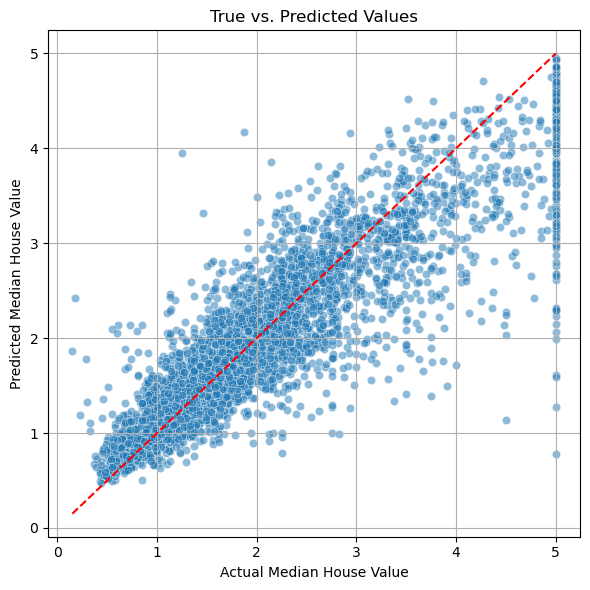

In [9]:
# Predictions and plot
y_pred = regressionmodel.predict(X_test).flatten()

plt.figure(figsize=(6, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--', color='red')
plt.xlabel("Actual Median House Value")
plt.ylabel("Predicted Median House Value")
plt.title("True vs. Predicted Values")
plt.grid(True)
plt.tight_layout()
plt.show()

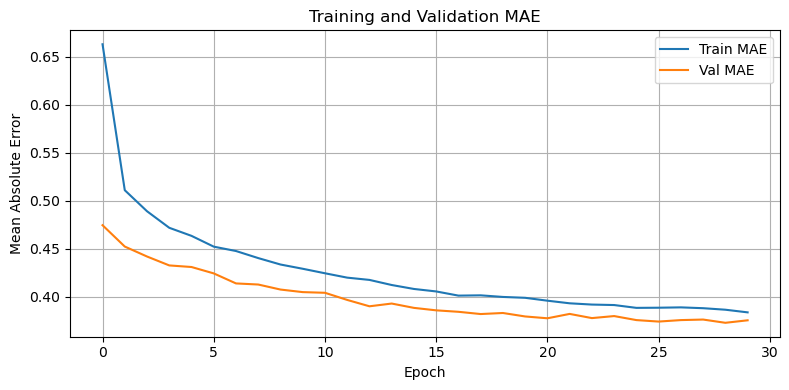

In [10]:
# Training curve
plt.figure(figsize=(8, 4))
plt.plot(history.history['mae'], label='Train MAE')
plt.plot(history.history['val_mae'], label='Val MAE')
plt.title("Training and Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("Mean Absolute Error")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [11]:
regressionmodel.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,421 (111.02 KB)

 Trainable params: 9,473 (37.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 18,948 (74.02 KB)

In [ ]:
# Save model summary (optional)
with open("model_summary_regression.txt", "w") as f:
    regressionmodel.summary(print_fn=lambda line: f.write(line + "\n"))

print("Model summary saved to model_summary_regression.txt")

In [ ]:
# end of demo with linear regression for tabular data with version-tab